# 🧪 06 - Visualization Lab: The Penguin Report, in Pictures

In the Module 07 lab you described the Palmer Penguins with **numbers**: a data dictionary, summary tables, outliers within species, and a Simpson's paradox in the bill measurements. Now the research team wants a **visual report**: a small set of figures that tells the same story to someone who'll never read a table.

You'll build it with everything from notebooks 01–05, check each figure against your Module 07 numbers, and save a finished figure set.

## ✅ Learning Goals
- Turn a numeric finding into the chart that shows it best
- Use one consistent, colorblind-safe palette and category order across a whole report
- Build single charts, small multiples, and a multi-panel summary figure
- Write titles that state findings, and check every chart against the numbers
- Export a complete, labeled figure set

```text
Load & clean (Module 07 lab) → Set report style → Distributions (03)
     → Group comparisons (03, 04) → Composition (02) → Relationships (04)
     → The paradox (04) → Summary figure (01) → Export
```

## 0. Setup
Everything this lab saves goes into **`06-OutputFiles`**. Upload that folder along with this notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

OUT = Path('06-OutputFiles')
OUT.mkdir(exist_ok=True)

MEASUREMENTS = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

# Same cleaning as the Module 07 lab
penguins = pd.read_csv('penguins.csv').dropna(subset=MEASUREMENTS).copy()
penguins['sex'] = penguins['sex'].str.title()
print(penguins.shape)

(342, 7)


## 1. Set the Report Style Once
A report looks like **one** report when every chart uses the same theme, the same category order, and the same color for the same species (notebook 05). Define them once, at the top, and use them everywhere:

In [2]:
sns.set_theme(style='whitegrid', context='notebook')

SPECIES = ['Adelie', 'Chinstrap', 'Gentoo']
SPECIES_COLORS = dict(zip(SPECIES, sns.color_palette('colorblind', 3)))
SEX_COLORS = {'Female': '#999999', 'Male': '#333333'}

LABELS = {
    'bill_length_mm': 'Bill length (mm)',
    'bill_depth_mm': 'Bill depth (mm)',
    'flipper_length_mm': 'Flipper length (mm)',
    'body_mass_g': 'Body mass (g)',
}


def finish(ax, title, subtitle=None):
    """Apply the report's title style to an ax (notebook 05)."""
    ax.set_title(title, loc='left', fontweight='bold', pad=22 if subtitle else 6)
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, color='gray')
    ax.spines[['top', 'right']].set_visible(False)

`finish()` is notebook 01's "functions that draw on an `ax`" idea: every chart gets the same title style with one line.

## 2. Figure 1: Two Groups Hiding in One Distribution
**Module 07 finding:** body mass is roughly symmetric overall (skew ≈ 0.47), and Gentoos are about 1,350 g heavier than the other two species.

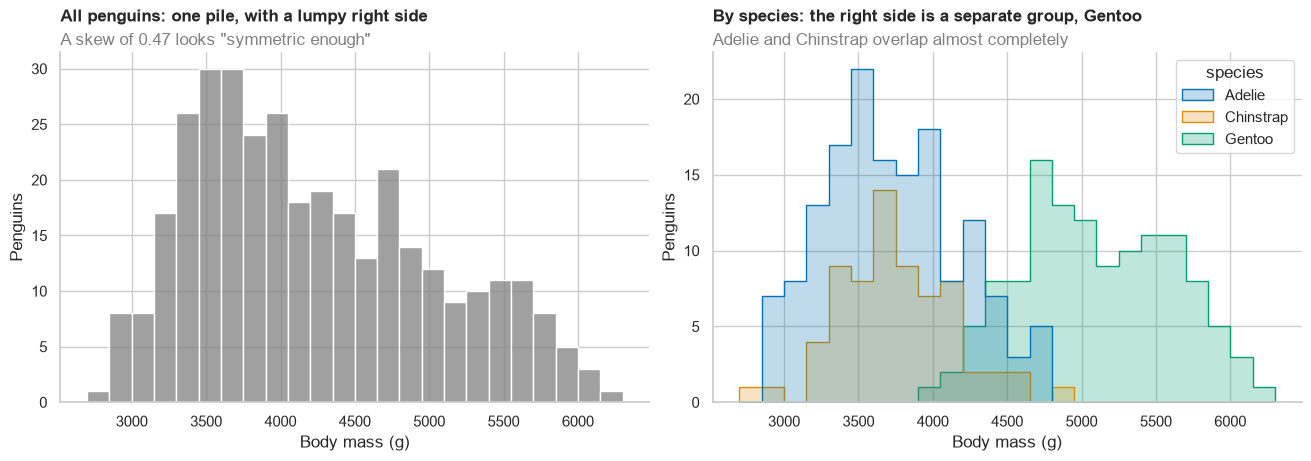

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True, layout='constrained')

sns.histplot(data=penguins, x='body_mass_g', binwidth=150, color='gray', ax=axes[0])
finish(axes[0], 'All penguins: one pile, with a lumpy right side', 'A skew of 0.47 looks "symmetric enough"')

sns.histplot(data=penguins, x='body_mass_g', hue='species', hue_order=SPECIES,
             palette=SPECIES_COLORS, binwidth=150, element='step', ax=axes[1])
finish(axes[1], 'By species: the right side is a separate group, Gentoo', 'Adelie and Chinstrap overlap almost completely')

for ax in axes:
    ax.set(xlabel=LABELS['body_mass_g'], ylabel='Penguins')

fig.savefig(OUT / 'fig1_body_mass_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

✅ **Check against the numbers:** the Gentoo group should center near the Module 07 Gentoo mean (about 5,076 g), and the Adelie/Chinstrap humps near 3,700 g. Do they?

## 3. Figure 2: Species and Sex
**Module 07 finding:** within every species, males are heavier (by about 400–800 g).

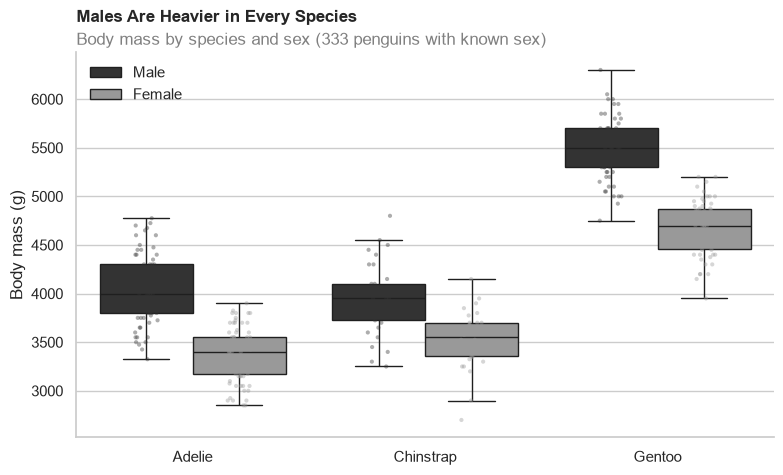

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=penguins.dropna(subset=['sex']), x='species', y='body_mass_g', hue='sex',
            order=SPECIES, palette=SEX_COLORS, showfliers=False, ax=ax)
sns.stripplot(data=penguins.dropna(subset=['sex']), x='species', y='body_mass_g', hue='sex',
              order=SPECIES, palette=SEX_COLORS, dodge=True, alpha=0.4, size=3,
              legend=False, ax=ax)
ax.set(xlabel='', ylabel=LABELS['body_mass_g'])
ax.legend(title='', frameon=False, loc='upper left')
finish(ax, 'Males Are Heavier in Every Species',
       f'Body mass by species and sex ({penguins["sex"].notna().sum()} penguins with known sex)')

fig.savefig(OUT / 'fig2_mass_by_species_sex.png', dpi=150, bbox_inches='tight')
plt.show()

The subtitle reports the sample size **after** dropping unknown sex, so the reader knows 9 penguins aren't in this chart (Module 07: always say what a summary is based on).

## 4. Figure 3: Where Each Species Lives
**Module 07 finding:** island and species are tangled together. Chinstraps were only measured on Dream, and Gentoos only on Biscoe.

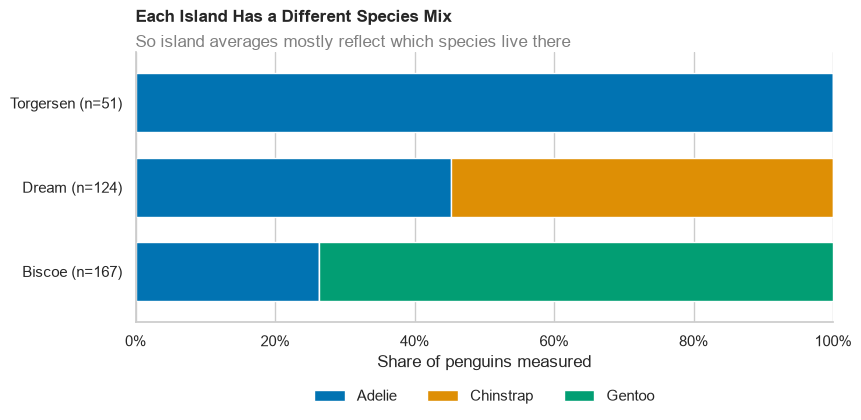

In [5]:
mix = pd.crosstab(penguins['island'], penguins['species'], normalize='index')[SPECIES]
counts = penguins['island'].value_counts()

fig, ax = plt.subplots(figsize=(9, 3.5))
mix.plot.barh(stacked=True, color=[SPECIES_COLORS[s] for s in SPECIES], width=0.7, ax=ax)
ax.set_yticks(range(len(mix)), [f'{island} (n={counts[island]})' for island in mix.index])
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(xmax=1))
ax.set(xlabel='Share of penguins measured', ylabel='')
ax.legend(title='', frameon=False, ncols=3, loc='upper center', bbox_to_anchor=(0.5, -0.2))
finish(ax, 'Each Island Has a Different Species Mix',
       'So island averages mostly reflect which species live there')

fig.savefig(OUT / 'fig3_species_by_island.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Figure 4: How the Measurements Relate
**Module 07 finding:** flipper length and body mass are very strongly correlated (r ≈ 0.87).

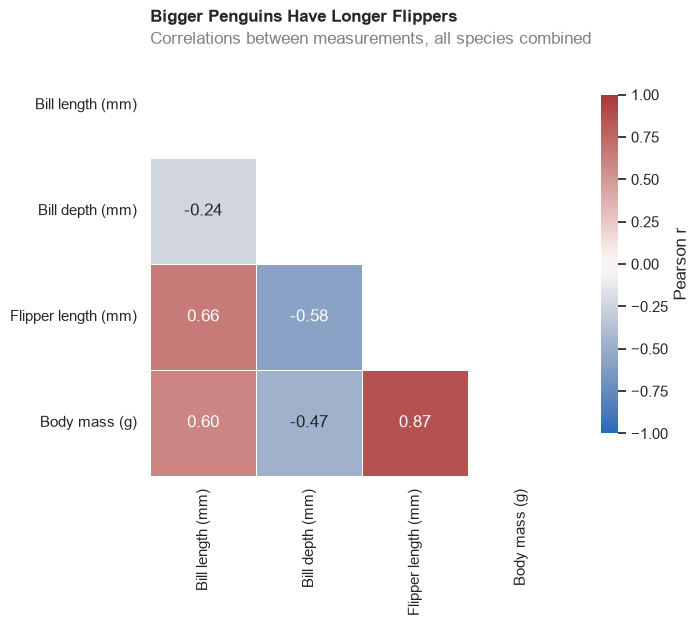

In [6]:
corr = penguins[MEASUREMENTS].rename(columns=LABELS).corr()
mask = np.triu(np.ones(corr.shape, dtype=bool))

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, center=0,
            square=True, linewidths=0.5, cbar_kws={'label': 'Pearson r', 'shrink': 0.8}, ax=ax)
finish(ax, 'Bigger Penguins Have Longer Flippers', 'Correlations between measurements, all species combined')
ax.spines[['left', 'bottom']].set_visible(False)
ax.grid(False)        # the whitegrid theme would draw lines through the masked cells

fig.savefig(OUT / 'fig4_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

Notice the subtitle: **all species combined.** You know from Module 07 that one of these numbers changes sign within species. That's the next figure, and it's yours to build.

---
## 🛠️ Your Figures
Sections 2–5 were worked examples. Sections 6 and 7 are yours. Use `SPECIES_COLORS`, `SPECIES`, `LABELS`, and `finish()` so they match the rest of the report.

## 6. Figure 5: The Paradox
Build a two-panel figure (`sharex=True, sharey=True`) of bill length vs. bill depth:
- **Left:** all penguins in gray, with one `regplot` trend line and the overall r in the subtitle.
- **Right:** colored by species, with one `regplot` line per species and each species' r in the legend.
- Titles that **state** the finding (for example, "Combined, Longer Bills Look Shallower" / "Within Every Species, Longer Bills Are Deeper").
- Save as `OUT / 'fig5_bill_paradox.png'`.

(Notebook 04 section 3 is your model, but use this report's style.)

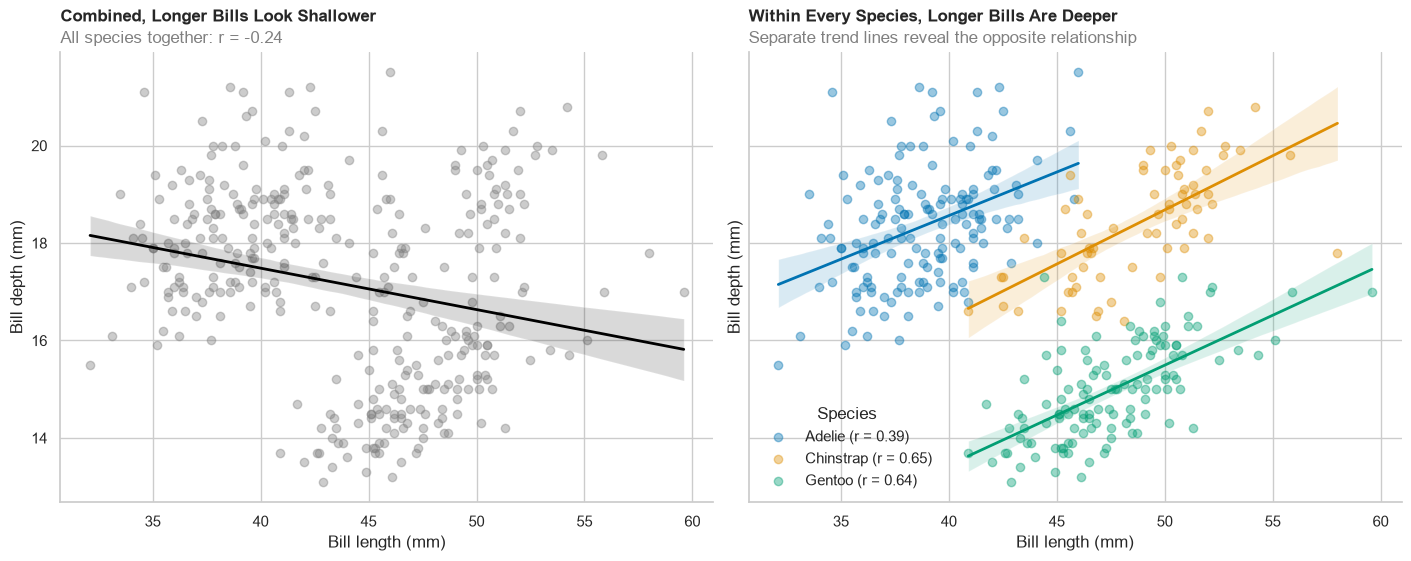

In [7]:
# Your Figure 5 here

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5.5),
    sharex=True,
    sharey=True,
    layout='constrained'
)

# Left: all penguins together
r_all = penguins['bill_length_mm'].corr(
    penguins['bill_depth_mm']
)

sns.regplot(
    data=penguins,
    x='bill_length_mm',
    y='bill_depth_mm',
    scatter_kws={'alpha': 0.4, 'color': 'gray'},
    line_kws={'color': 'black', 'linewidth': 2},
    ax=axes[0]
)

finish(
    axes[0],
    'Combined, Longer Bills Look Shallower',
    f'All species together: r = {r_all:.2f}'
)

# Right: separate lines for each species
for species in SPECIES:

    group = penguins[penguins['species'] == species]

    r = group['bill_length_mm'].corr(
        group['bill_depth_mm']
    )

    sns.regplot(
        data=group,
        x='bill_length_mm',
        y='bill_depth_mm',
        color=SPECIES_COLORS[species],
        scatter_kws={'alpha': 0.4},
        line_kws={'linewidth': 2},
        label=f'{species} (r = {r:.2f})',
        ax=axes[1]
    )

axes[1].legend(title='Species', frameon=False)

finish(
    axes[1],
    'Within Every Species, Longer Bills Are Deeper',
    'Separate trend lines reveal the opposite relationship'
)

# Label both axes
for ax in axes:
    ax.set(
        xlabel=LABELS['bill_length_mm'],
        ylabel=LABELS['bill_depth_mm']
    )

fig.savefig(
    OUT / 'fig5_bill_paradox.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

## 7. Figure 6: The One-Page Summary
Build a single summary figure with `plt.subplot_mosaic()` (notebook 01 Challenge). The skeleton below creates the layout. Fill in each panel:
- `'dist'`: body mass by species (KDE or step histogram)
- `'paradox'`: the species-colored bill scatter from Figure 5
- `'flipper'`: flipper length vs. body mass, colored by species
- `'sex'`: mean body mass by species and sex (`barplot` or `pointplot`)

Give the figure a `suptitle` with the single most important finding, and save it as `OUT / 'fig6_summary.png'`.

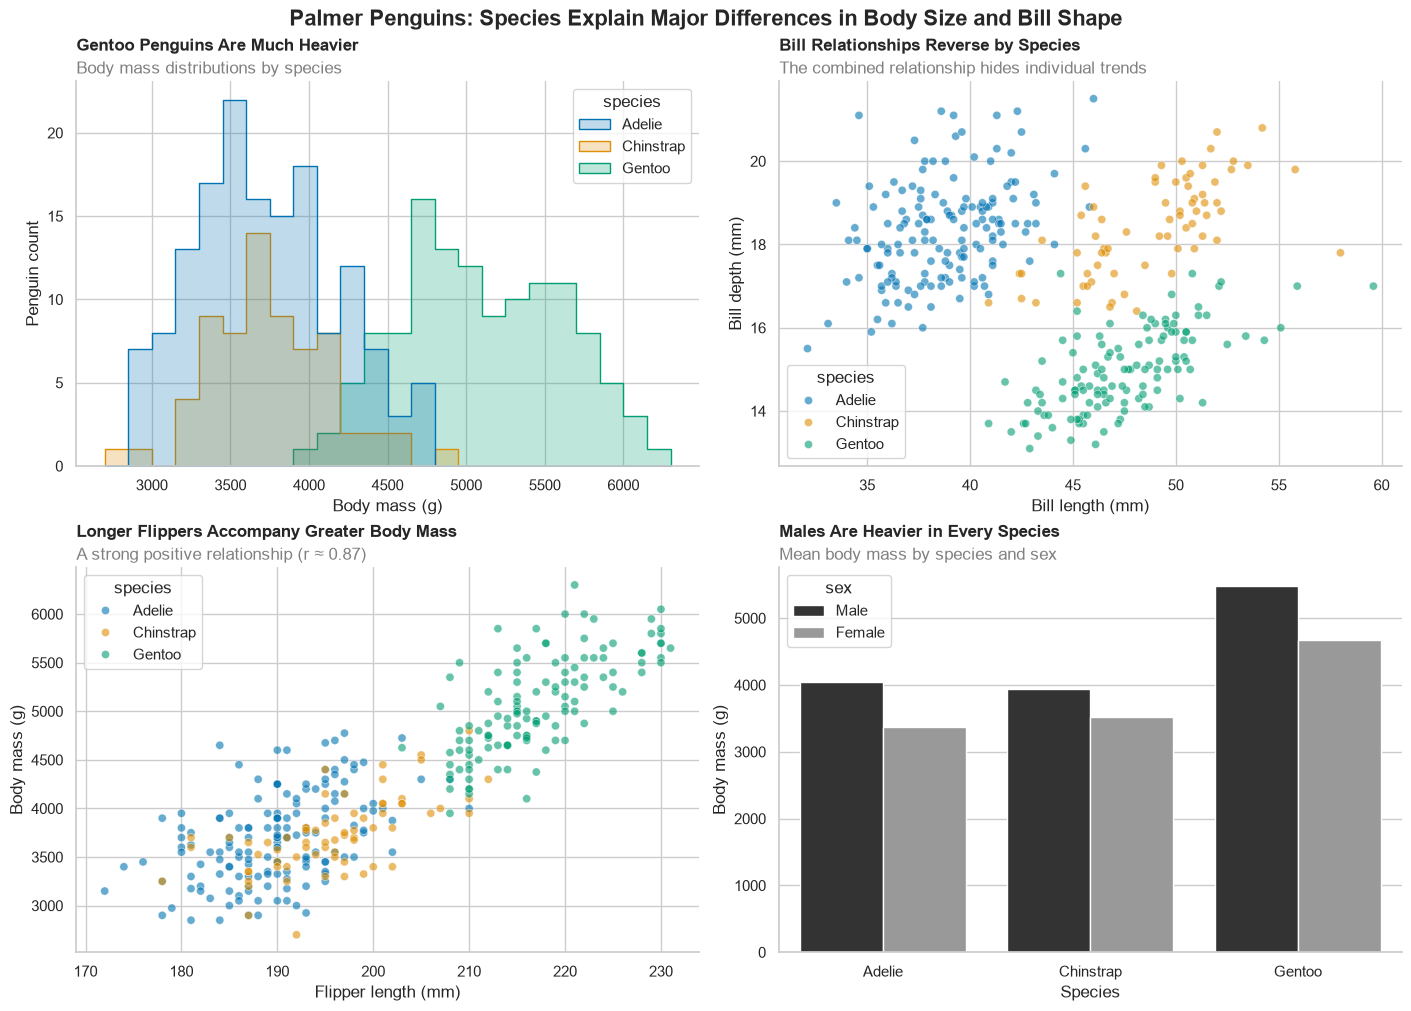

In [9]:
# fig, axd = plt.subplot_mosaic(
#     [['dist', 'paradox'],
#      ['flipper', 'sex']],
#     figsize=(14, 10), layout='constrained',
# )

# # TODO: draw on axd['dist'], axd['paradox'], axd['flipper'], and axd['sex']
# # TODO: fig.suptitle(...)
# # TODO: fig.savefig(OUT / 'fig6_summary.png', dpi=150, bbox_inches='tight')

# plt.show()

fig, axd = plt.subplot_mosaic(
    [['dist', 'paradox'],
     ['flipper', 'sex']],
    figsize=(14, 10),
    layout='constrained'
)

# Panel 1: Body mass distribution by species
sns.histplot(
    data=penguins,
    x='body_mass_g',
    hue='species',
    hue_order=SPECIES,
    palette=SPECIES_COLORS,
    element='step',
    binwidth=150,
    ax=axd['dist']
)

finish(
    axd['dist'],
    'Gentoo Penguins Are Much Heavier',
    'Body mass distributions by species'
)

axd['dist'].set(
    xlabel=LABELS['body_mass_g'],
    ylabel='Penguin count'
)

# Panel 2: Bill length vs. bill depth
sns.scatterplot(
    data=penguins,
    x='bill_length_mm',
    y='bill_depth_mm',
    hue='species',
    hue_order=SPECIES,
    palette=SPECIES_COLORS,
    alpha=0.6,
    s=35,
    ax=axd['paradox']
)

finish(
    axd['paradox'],
    'Bill Relationships Reverse by Species',
    'The combined relationship hides individual trends'
)

axd['paradox'].set(
    xlabel=LABELS['bill_length_mm'],
    ylabel=LABELS['bill_depth_mm']
)

# Panel 3: Flipper length vs. body mass
sns.scatterplot(
    data=penguins,
    x='flipper_length_mm',
    y='body_mass_g',
    hue='species',
    hue_order=SPECIES,
    palette=SPECIES_COLORS,
    alpha=0.6,
    s=35,
    ax=axd['flipper']
)

finish(
    axd['flipper'],
    'Longer Flippers Accompany Greater Body Mass',
    'A strong positive relationship (r ≈ 0.87)'
)

axd['flipper'].set(
    xlabel=LABELS['flipper_length_mm'],
    ylabel=LABELS['body_mass_g']
)

# Panel 4: Average body mass by species and sex
sns.barplot(
    data=penguins.dropna(subset=['sex']),
    x='species',
    y='body_mass_g',
    hue='sex',
    order=SPECIES,
    palette=SEX_COLORS,
    errorbar=None,
    ax=axd['sex']
)

finish(
    axd['sex'],
    'Males Are Heavier in Every Species',
    'Mean body mass by species and sex'
)

axd['sex'].set(
    xlabel='Species',
    ylabel=LABELS['body_mass_g']
)

# Main report title
fig.suptitle(
    'Palmer Penguins: Species Explain Major Differences in Body Size and Bill Shape',
    fontsize=16,
    fontweight='bold'
)

fig.savefig(
    OUT / 'fig6_summary.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

## ❓ Lab Questions
Answer each in the Markdown cell below:
1. Figure 1: why did a skew of 0.47 (Module 07) fail to warn you that two groups were mixed together? What kind of chart reveals it, and what kind of statistic can't?
2. Figure 2: why does the chart use `showfliers=False` on the box plot? What would go wrong without it?
3. Figure 3: why is a 100% stacked bar a better choice here than a grouped count bar chart? What did adding `n=` to the labels fix?
4. Figure 5: explain Simpson's paradox from your chart alone, as if to someone who has never seen the numbers.
5. Which was easier to **find** the paradox with: the Module 07 tables or the Module 08 chart? Which is better as **evidence**? Why might you want both?
6. Pick one figure and go through the notebook 05 checklist. Which item did you have to fix last?

*Your answers here.*

1. Figure 1: Why did a skew of 0.47 fail to warn you that two groups were mixed together? What kind of chart reveals it, and what kind of statistic can't?

A skew of 0.47 describes the overall distribution and suggests it is fairly close to symmetric. However, it does not show that the data contain different groups with different body masses. A histogram with different colors for each species reveals the separate distributions. A single summary statistic, such as skewness or the mean, cannot show the individual groups clearly.

2. Figure 2: Why does the chart use showfliers=False on the box plot? What would go wrong without it?

The chart uses showfliers=False to prevent outliers from being displayed twice because the strip plot already shows individual penguin observations. Without it, the outliers would overlap with the individual points, making the chart more cluttered and harder to read.

3. Figure 3: Why is a 100% stacked bar a better choice here than a grouped count bar chart? What did adding n= to the labels fix?

A 100% stacked bar chart makes it easier to compare the proportion of each species on each island, even when the islands have different sample sizes. A grouped count bar chart shows the total number of penguins instead of their proportions. Adding n= to the labels shows the actual sample size for each island, helping readers understand how many observations each percentage represents.

4. Figure 5: Explain Simpson's paradox from your chart alone, as if to someone who has never seen the numbers.

When all penguins are combined, longer bills appear to be associated with shallower bills. However, when we separate the penguins by species, every species shows the opposite relationship: longer bills are associated with deeper bills. This happens because the species have different bill characteristics and their groups are positioned differently on the chart. Combining the groups hides their individual relationships and reverses the overall trend.

5. Which was easier to find the paradox with: the Module 07 tables or the Module 08 chart? Which is better as evidence? Why might you want both?

The Module 07 tables were useful for finding the paradox because they provided exact correlation values for the combined dataset and each species. However, the Module 08 chart is better for communicating the paradox because it makes the opposite trends visible immediately. Both are useful because tables provide precise numerical evidence while charts make patterns easier to understand.

6. Pick one figure and go through the notebook 05 checklist. Which item did you have to fix last?

I chose Figure 5. I checked that the chart had a clear question, the correct chart type, descriptive titles, labeled axes, consistent scales, and colorblind-safe species colors. The last item I focused on was reducing clutter by making the species trend lines and legend easy to distinguish.

## 🏋️ Practice

### Practice 1 — Flipper Length by Species (easy)
Make a violin plot of `flipper_length_mm` by species, with `order=SPECIES` and `palette=SPECIES_COLORS`. Write a title that states the finding, using `finish()`.

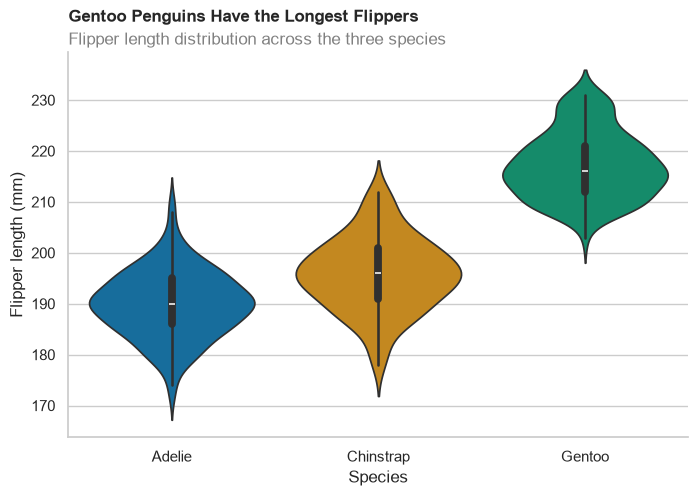

In [10]:
# Your code here

fig, ax = plt.subplots(figsize=(8, 5))

sns.violinplot(
    data=penguins,
    x='species',
    y='flipper_length_mm',
    order=SPECIES,
    hue='species',
    palette=SPECIES_COLORS,
    legend=False,
    ax=ax
)

ax.set(
    xlabel='Species',
    ylabel=LABELS['flipper_length_mm']
)

finish(
    ax,
    'Gentoo Penguins Have the Longest Flippers',
    'Flipper length distribution across the three species'
)

fig.savefig(
    OUT / 'practice_flipper_length.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

Finding: Gentoo penguins generally have longer flippers than Adelie and Chinstrap penguins. The violin plot shows the distribution and density of flipper lengths for each species.

### Practice 2 — Small Multiples (medium)
Use `sns.displot()` to draw `bill_depth_mm` with `col='species'` and `hue='sex'`, using the report's colors and order. Save it as `OUT / 'practice_bill_depth_grid.png'`.

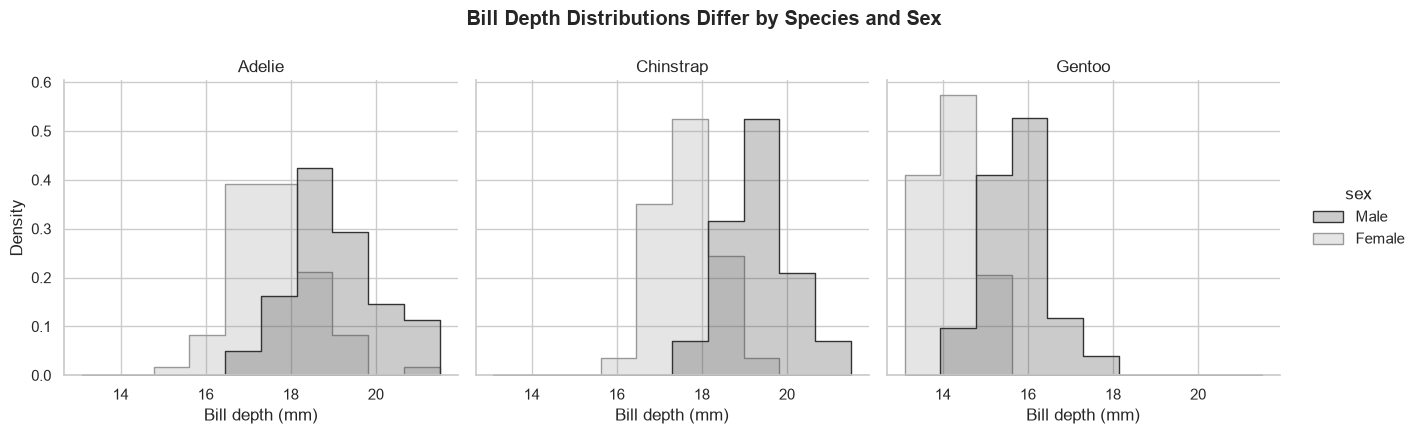

In [11]:
# Your code here

g = sns.displot(
    data=penguins.dropna(subset=['sex']),
    x='bill_depth_mm',
    hue='sex',
    col='species',
    col_order=SPECIES,
    palette=SEX_COLORS,
    kind='hist',
    element='step',
    stat='density',
    common_norm=False,
    height=4,
    aspect=1.1
)

g.set_axis_labels(
    LABELS['bill_depth_mm'],
    'Density'
)

g.set_titles('{col_name}')

g.figure.suptitle(
    'Bill Depth Distributions Differ by Species and Sex',
    y=1.08,
    fontweight='bold'
)

g.savefig(
    OUT / 'practice_bill_depth_grid.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

Finding: Bill depth distributions differ across the three species. Separating the charts by species makes it easier to compare male and female penguins without mixing the groups together.

### Practice 3 — A Fair Island Comparison (harder)
Module 07's lab Practice 2 compared Adelie body mass across islands (the only species on all three). Make the chart version: a box + strip plot of Adelie `body_mass_g` by island, with sample sizes in the tick labels. Does the chart agree with your numbers?

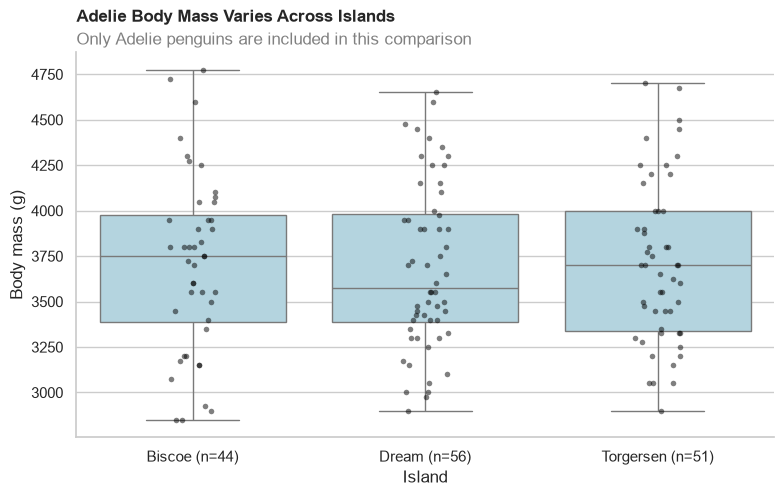

In [12]:
# Your code here

# Keep only Adelie penguins
adelie = penguins[penguins['species'] == 'Adelie'].copy()

# Count penguins on each island
island_counts = adelie['island'].value_counts()

# Define island order
ISLAND_ORDER = ['Biscoe', 'Dream', 'Torgersen']

# Create labels with sample sizes
island_labels = [
    f'{island} (n={island_counts.get(island, 0)})'
    for island in ISLAND_ORDER
]

fig, ax = plt.subplots(figsize=(9, 5))

# Box plot
sns.boxplot(
    data=adelie,
    x='island',
    y='body_mass_g',
    order=ISLAND_ORDER,
    color='lightblue',
    showfliers=False,
    ax=ax
)

# Individual observations
sns.stripplot(
    data=adelie,
    x='island',
    y='body_mass_g',
    order=ISLAND_ORDER,
    color='black',
    alpha=0.5,
    jitter=True,
    size=4,
    ax=ax
)

ax.set_xticks(range(len(ISLAND_ORDER)))
ax.set_xticklabels(island_labels)

ax.set(
    xlabel='Island',
    ylabel=LABELS['body_mass_g']
)

finish(
    ax,
    'Adelie Body Mass Varies Across Islands',
    'Only Adelie penguins are included in this comparison'
)

fig.savefig(
    OUT / 'practice_adelie_island_mass.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

In [13]:
adelie.groupby('island')['body_mass_g'].agg(
    ['count', 'mean', 'median', 'std']
).round(2)

,count,mean,median,std
island,,,,
Biscoe,44,3709.66,3750.0,487.73
Dream,56,3688.39,3575.0,455.15
Torgersen,51,3706.37,3700.0,445.11


Finding:

The chart shows the distribution of Adelie body mass across Biscoe, Dream, and Torgersen islands. The box plots and individual observations allow us to compare their centers, variation, and outliers.

The chart should agree with the Module 07 numerical results because both use the same Adelie penguin observations.

## ✏️ Challenge Task
Make a **pair plot** of the four measurements with `hue='species'`, `corner=True`, and the report palette. Find the pair of measurements that separates all three species most cleanly, then make a **polished** single scatter plot of just that pair, with a finding title and direct species labels instead of a legend (hint: `ax.text()` at each species' mean position). Save it as `OUT / 'fig7_best_separator.png'`.

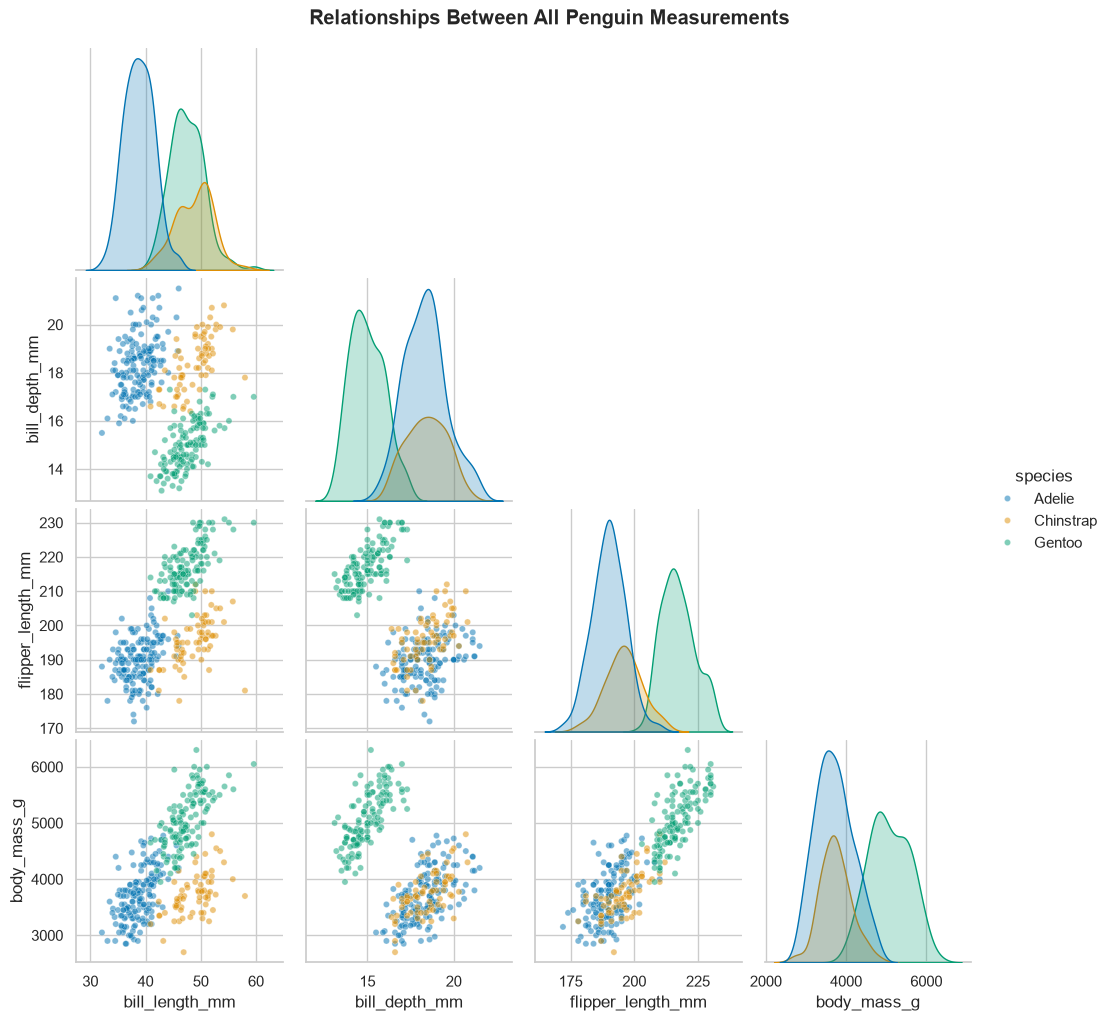

In [14]:
# Your code here

g = sns.pairplot(
    penguins,
    vars=MEASUREMENTS,
    hue='species',
    hue_order=SPECIES,
    palette=SPECIES_COLORS,
    corner=True,
    height=2.5,
    plot_kws={'alpha': 0.5, 's': 20}
)

g.figure.suptitle(
    'Relationships Between All Penguin Measurements',
    y=1.02,
    fontweight='bold'
)

plt.show()

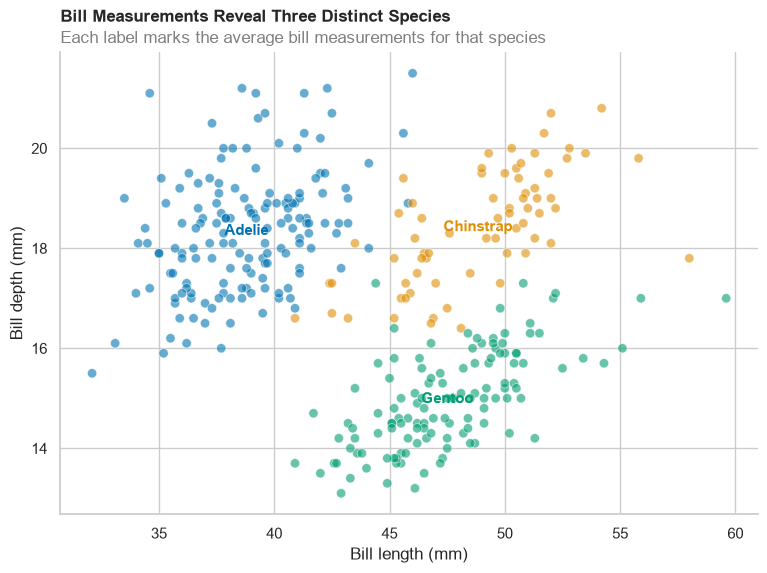

In [15]:
# Select the two measurements
x_col = 'bill_length_mm'
y_col = 'bill_depth_mm'

# Calculate the mean position of each species
species_means = penguins.groupby('species')[
    [x_col, y_col]
].mean()

fig, ax = plt.subplots(figsize=(9, 6))

# Draw the scatter plot
sns.scatterplot(
    data=penguins,
    x=x_col,
    y=y_col,
    hue='species',
    hue_order=SPECIES,
    palette=SPECIES_COLORS,
    alpha=0.6,
    s=45,
    legend=False,
    ax=ax
)

# Add direct species labels at their mean positions
for species in SPECIES:

    x_mean = species_means.loc[species, x_col]
    y_mean = species_means.loc[species, y_col]

    ax.text(
        x_mean,
        y_mean,
        species,
        color=SPECIES_COLORS[species],
        fontsize=11,
        fontweight='bold',
        ha='center',
        va='center'
    )

ax.set(
    xlabel=LABELS[x_col],
    ylabel=LABELS[y_col]
)

finish(
    ax,
    'Bill Measurements Reveal Three Distinct Species',
    'Each label marks the average bill measurements for that species'
)

fig.savefig(
    OUT / 'fig7_best_separator.png',
    dpi=150,
    bbox_inches='tight'
)

plt.show()

Bill length and bill depth help distinguish the three penguin species because they have different bill characteristics. The scatter plot makes these differences visible, particularly the shallower bills of Gentoo penguins compared with the other species.

## 🔥 Challenge (Optional) — A Visual Report on New Data
Pick `titanic.csv` or `pokemon.csv` (copy it into this folder, or use the path `../07-Describing_Data/`). Ask **three** questions, and answer each with one finished chart (finding title, consistent palette, honest scales), saved to `OUT` with a `challenge_` prefix. Write one sentence per chart summarizing the finding.

In [ ]:
# Your code here

*Your three findings here.*

## 📦 Check Your Output Files
Run this last. Everything you saved should be inside `06-OutputFiles`. Upload that folder along with this notebook.

In [16]:
for path in sorted(OUT.rglob('*')):
    print(path)

06-OutputFiles\fig1_body_mass_distribution.png
06-OutputFiles\fig2_mass_by_species_sex.png
06-OutputFiles\fig3_species_by_island.png
06-OutputFiles\fig4_correlation_heatmap.png
06-OutputFiles\fig5_bill_paradox.png
06-OutputFiles\fig6_summary.png
06-OutputFiles\fig7_best_separator.png
06-OutputFiles\practice_adelie_island_mass.png
06-OutputFiles\practice_bill_depth_grid.png
06-OutputFiles\practice_flipper_length.png


---
### 📝 Summary
This lab turned a numeric report into a visual one:
- **One style for the whole report**: a theme, a category order, a palette dictionary, and a `finish()` helper
- **Distributions** revealed a second group that the skew statistic hid
- **Box + strip** showed both the summary and every penguin
- **Composition** made the island/species confounder visible, with sample sizes
- **Heatmap + paradox figure**: the combined correlation, and why it misleads
- **Every chart was checked against the Module 07 numbers**: charts and statistics work best together

🎓 That's Module 08, and the end of the course's core material. For the **final project**, you'll run this whole cycle (load, clean, describe, visualize, explain) on a dataset of your own.